In [63]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from google.colab import files

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)
print("Libraries imported successfully!")

Libraries imported successfully!


In [64]:
uploaded = files.upload()

Saving train.csv to train (3).csv


In [65]:
df = pd.read_csv("train.csv")

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)
display(df.head())

Dataset loaded successfully!
Dataset shape: (1460, 81)


,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


In [66]:
print("First five rows:")
display(df.head())

print("Last five rows:")
display(df.tail())

print("Dataset information:")
df.info()

print("Duplicate rows:", df.duplicated().sum())

First five rows:


,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


Last five rows:


,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
1455,1456,60,RL,62.0,7917,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,8,2007,WD,Normal,175000
1456,1457,20,RL,85.0,13175,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,MnPrv,NaN,0,2,2010,WD,Normal,210000
1457,1458,70,RL,66.0,9042,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,GdPrv,Shed,2500,5,2010,WD,Normal,266500
1458,1459,20,RL,68.0,9717,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,4,2010,WD,Normal,142125
1459,1460,20,RL,75.0,9937,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,6,2008,WD,Normal,147500


Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1460 entries, 0 to 1459
Data columns (total 81 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             1460 non-null   int64  
 1   MSSubClass     1460 non-null   int64  
 2   MSZoning       1460 non-null   object 
 3   LotFrontage    1201 non-null   float64
 4   LotArea        1460 non-null   int64  
 5   Street         1460 non-null   object 
 6   Alley          91 non-null     object 
 7   LotShape       1460 non-null   object 
 8   LandContour    1460 non-null   object 
 9   Utilities      1460 non-null   object 
 10  LotConfig      1460 non-null   object 
 11  LandSlope      1460 non-null   object 
 12  Neighborhood   1460 non-null   object 
 13  Condition1     1460 non-null   object 
 14  Condition2     1460 non-null   object 
 15  BldgType       1460 non-null   object 
 16  HouseStyle     1460 non-null   object 
 17  OverallQual    1460 non-null   

In [67]:
missing_values = df.isnull().sum()
missing_summary = pd.DataFrame({
    "Missing Count": missing_values,
    "Missing Percentage": (missing_values / len(df) * 100).round(2)
})
missing_summary = missing_summary[missing_summary["Missing Count"] > 0].sort_values(
    "Missing Count", ascending=False
)
display(missing_summary)

print("Rows:", df.shape[0])
print("Columns:", df.shape[1])
print("Columns containing missing values:", len(missing_summary))

,Missing Count,Missing Percentage
PoolQC,1453,99.52
MiscFeature,1406,96.30
Alley,1369,93.77
Fence,1179,80.75
MasVnrType,872,59.73
FireplaceQu,690,47.26
LotFrontage,259,17.74
GarageType,81,5.55
GarageYrBlt,81,5.55
GarageFinish,81,5.55


Rows: 1460
Columns: 81
Columns containing missing values: 19


In [68]:
numeric_cols = df.select_dtypes(include=["number"]).columns.tolist()
categorical_cols = df.select_dtypes(include=["object"]).columns.tolist()

ordinal_cols = ["OverallQual", "OverallCond", "ExterQual", "ExterCond",
                "BsmtQual", "BsmtCond", "HeatingQC", "KitchenQual",
                "FireplaceQu", "GarageQual", "GarageCond", "PoolQC", "Fence"]

print("Numerical columns:", len(numeric_cols))
print("Categorical columns:", len(categorical_cols))
print("Ordinal columns present:", [c for c in ordinal_cols if c in df.columns])

Numerical columns: 38
Categorical columns: 43
Ordinal columns present: ['OverallQual', 'OverallCond', 'ExterQual', 'ExterCond', 'BsmtQual', 'BsmtCond', 'HeatingQC', 'KitchenQual', 'FireplaceQu', 'GarageQual', 'GarageCond', 'PoolQC', 'Fence']


In [69]:
variable_summary = []

for col in df.columns:
    if col in ordinal_cols:
        variable_type = "Ordinal"
    elif col in numeric_cols:
        variable_type = "Numerical"
    else:
        variable_type = "Categorical"

    examples = df[col].dropna().unique()[:5].tolist()
    variable_summary.append({
        "Column Name": col,
        "Variable Type": variable_type,
        "Unique Values": df[col].nunique(),
        "Example Values": examples
    })

variable_summary = pd.DataFrame(variable_summary)
display(variable_summary)
display(variable_summary["Variable Type"].value_counts().to_frame("Number of Columns"))

,Column Name,Variable Type,Unique Values,Example Values
0,Id,Numerical,1460,"[1, 2, 3, 4, 5]"
1,MSSubClass,Numerical,15,"[60, 20, 70, 50, 190]"
2,MSZoning,Categorical,5,"[RL, RM, C (all), FV, RH]"
3,LotFrontage,Numerical,110,"[65.0, 80.0, 68.0, 60.0, 84.0]"
4,LotArea,Numerical,1073,"[8450, 9600, 11250, 9550, 14260]"
...,...,...,...,...
76,MoSold,Numerical,12,"[2, 5, 9, 12, 10]"
77,YrSold,Numerical,5,"[2008, 2007, 2006, 2009, 2010]"
78,SaleType,Categorical,9,"[WD, New, COD, ConLD, ConLI]"
79,SaleCondition,Categorical,6,"[Normal, Abnorml, Partial, AdjLand, Alloca]"


,Number of Columns
Variable Type,
Numerical,36
Categorical,32
Ordinal,13


In [70]:
display(df.describe().T)

,count,mean,std,min,25%,50%,75%,max
Id,1460.0,730.500000,421.610009,1.0,365.75,730.5,1095.25,1460.0
MSSubClass,1460.0,56.897260,42.300571,20.0,20.00,50.0,70.00,190.0
LotFrontage,1201.0,70.049958,24.284752,21.0,59.00,69.0,80.00,313.0
LotArea,1460.0,10516.828082,9981.264932,1300.0,7553.50,9478.5,11601.50,215245.0
OverallQual,1460.0,6.099315,1.382997,1.0,5.00,6.0,7.00,10.0
OverallCond,1460.0,5.575342,1.112799,1.0,5.00,5.0,6.00,9.0
YearBuilt,1460.0,1971.267808,30.202904,1872.0,1954.00,1973.0,2000.00,2010.0
YearRemodAdd,1460.0,1984.865753,20.645407,1950.0,1967.00,1994.0,2004.00,2010.0
MasVnrArea,1452.0,103.685262,181.066207,0.0,0.00,0.0,166.00,1600.0
BsmtFinSF1,1460.0,443.639726,456.098091,0.0,0.00,383.5,712.25,5644.0


In [71]:
selected_columns = ["SalePrice", "GrLivArea", "LotArea"]

for col in selected_columns:
    series = df[col].dropna()
    q1 = series.quantile(0.25)
    q3 = series.quantile(0.75)

    print("\\n", "=" * 45)
    print("Column:", col)
    print("Mean:", round(series.mean(), 2))
    print("Median:", round(series.median(), 2))
    print("Mode:", series.mode().iloc[0])
    print("Standard deviation:", round(series.std(), 2))
    print("Variance:", round(series.var(), 2))
    print("Range:", series.max() - series.min())
    print("IQR:", q3 - q1)
    print("Skewness:", round(series.skew(), 3))
    print("Kurtosis:", round(series.kurtosis(), 3))

\n =============================================
Column: SalePrice
Mean: 180921.2
Median: 163000.0
Mode: 140000
Standard deviation: 79442.5
Variance: 6311111264.3
Range: 720100
IQR: 84025.0
Skewness: 1.883
Kurtosis: 6.536
\n =============================================
Column: GrLivArea
Mean: 1515.46
Median: 1464.0
Mode: 864
Standard deviation: 525.48
Variance: 276129.63
Range: 5308
IQR: 647.25
Skewness: 1.367
Kurtosis: 4.895
\n =============================================
Column: LotArea
Mean: 10516.83
Median: 9478.5
Mode: 7200
Standard deviation: 9981.26
Variance: 99625649.65
Range: 213945
IQR: 4048.0
Skewness: 12.208
Kurtosis: 203.243


In [72]:
print("Neighborhood counts:")
display(df["Neighborhood"].value_counts().to_frame("Count"))

print("Most common neighborhood:", df["Neighborhood"].mode()[0])

print("\\nHouse style counts:")
display(df["HouseStyle"].value_counts().to_frame("Count"))

print("Most common house style:", df["HouseStyle"].mode()[0])

Neighborhood counts:


,Count
Neighborhood,
NAmes,225
CollgCr,150
OldTown,113
Edwards,100
Somerst,86
Gilbert,79
NridgHt,77
Sawyer,74
NWAmes,73


Most common neighborhood: NAmes
\nHouse style counts:


,Count
HouseStyle,
1Story,726
2Story,445
1.5Fin,154
SLvl,65
SFoyer,37
1.5Unf,14
2.5Unf,11
2.5Fin,8


Most common house style: 1Story


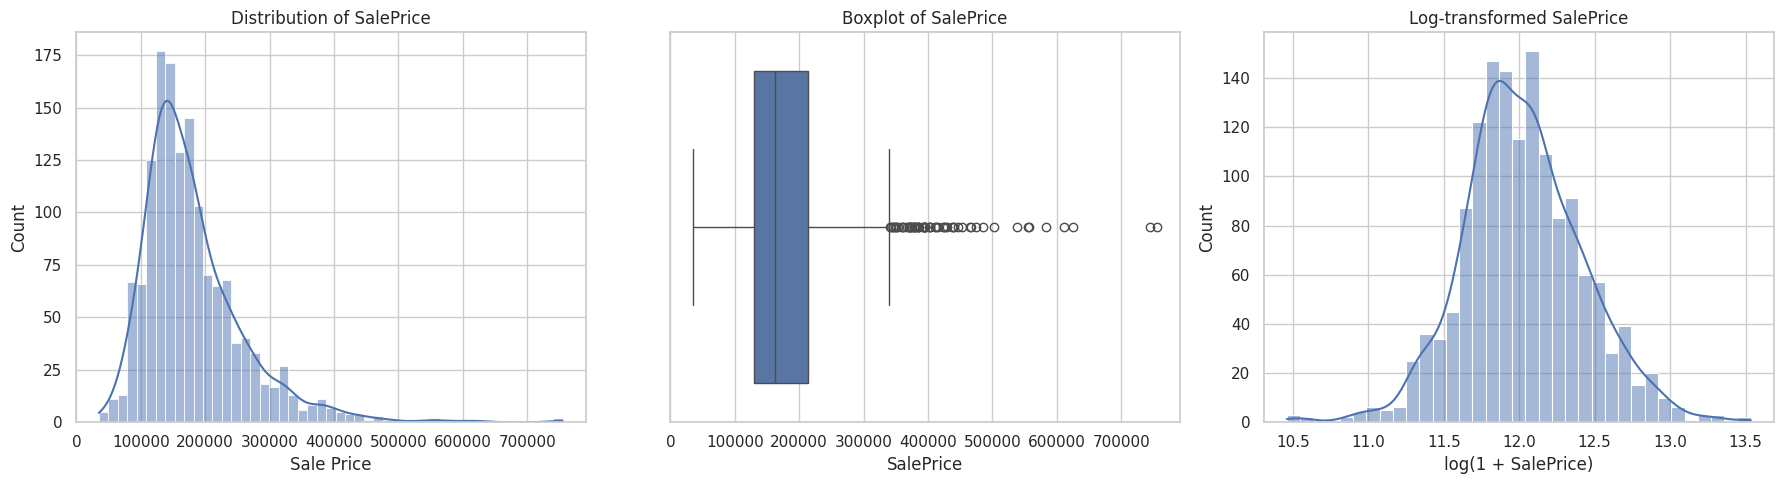

SalePrice skewness: 1.883
Log SalePrice skewness: 0.121


In [73]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

sns.histplot(df["SalePrice"], kde=True, ax=axes[0])
axes[0].set_title("Distribution of SalePrice")
axes[0].set_xlabel("Sale Price")

sns.boxplot(x=df["SalePrice"], ax=axes[1])
axes[1].set_title("Boxplot of SalePrice")

sns.histplot(np.log1p(df["SalePrice"]), kde=True, ax=axes[2])
axes[2].set_title("Log-transformed SalePrice")
axes[2].set_xlabel("log(1 + SalePrice)")

plt.tight_layout()
plt.show()

print("SalePrice skewness:", round(df["SalePrice"].skew(), 3))
print("Log SalePrice skewness:", round(np.log1p(df["SalePrice"]).skew(), 3))

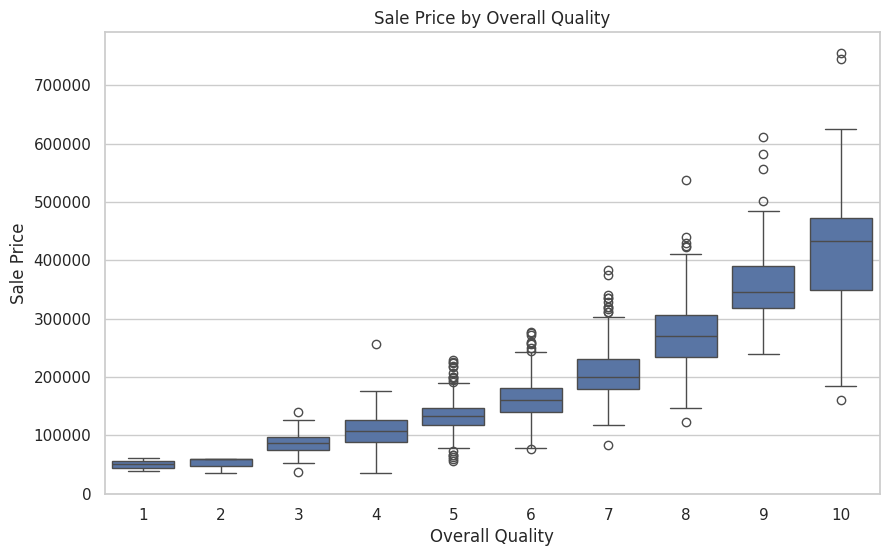

In [74]:
plt.figure(figsize=(10, 6))
sns.boxplot(data=df, x="OverallQual", y="SalePrice")
plt.title("Sale Price by Overall Quality")
plt.xlabel("Overall Quality")
plt.ylabel("Sale Price")
plt.show()

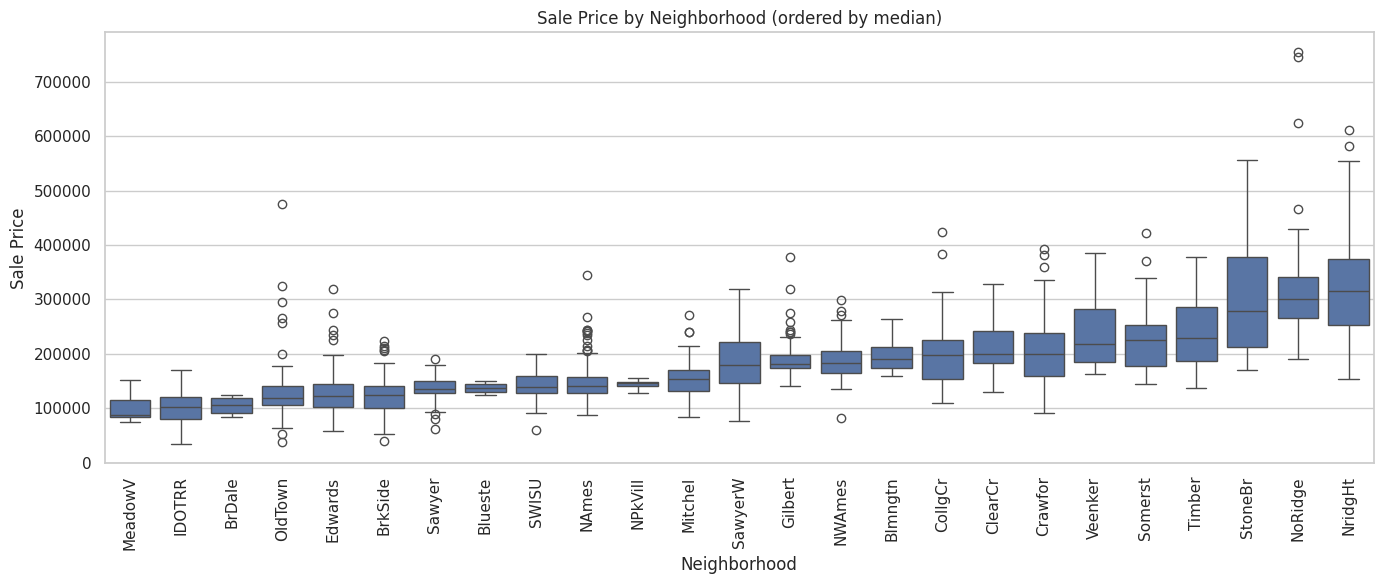

In [75]:
neighborhood_order = df.groupby("Neighborhood")["SalePrice"].median().sort_values().index

plt.figure(figsize=(14, 6))
sns.boxplot(data=df, x="Neighborhood", y="SalePrice", order=neighborhood_order)
plt.title("Sale Price by Neighborhood (ordered by median)")
plt.xlabel("Neighborhood")
plt.ylabel("Sale Price")
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

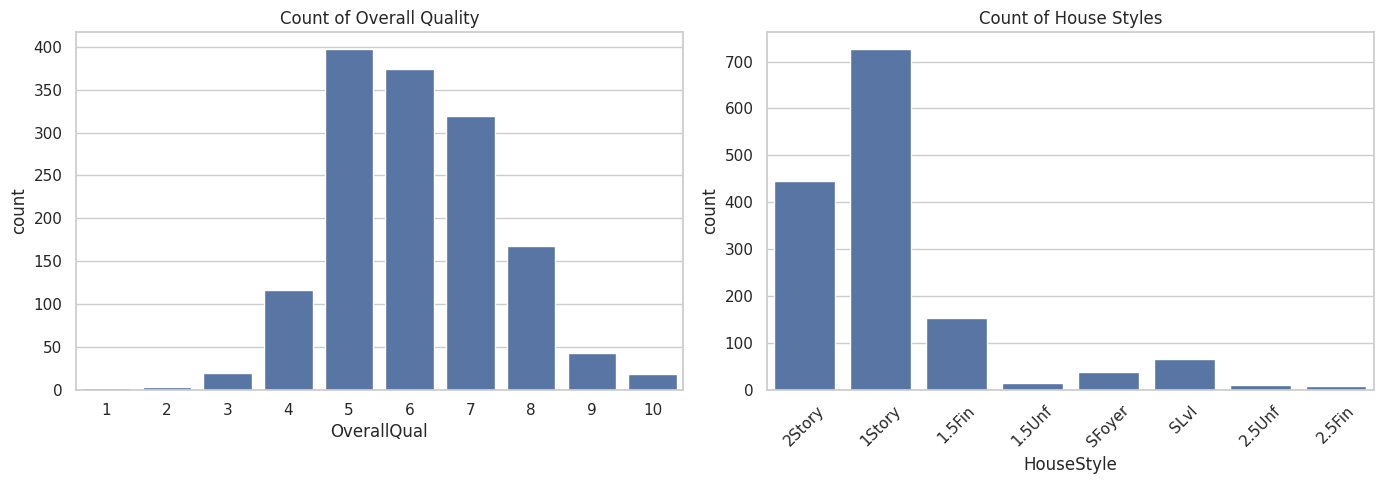

In [76]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.countplot(data=df, x="OverallQual", ax=axes[0])
axes[0].set_title("Count of Overall Quality")
sns.countplot(data=df, x="HouseStyle", ax=axes[1])
axes[1].set_title("Count of House Styles")
axes[1].tick_params(axis="x", rotation=45)
plt.tight_layout()
plt.show()

In [77]:
numeric_data = df.select_dtypes(include=["number"])
cov_matrix = numeric_data.cov()
corr_matrix = numeric_data.corr()

saleprice_corr = corr_matrix["SalePrice"].drop("SalePrice")
top_corr = saleprice_corr.reindex(saleprice_corr.abs().sort_values(ascending=False).index)

print("Top 10 numerical features correlated with SalePrice:")
display(top_corr.head(10).to_frame("Correlation with SalePrice"))

Top 10 numerical features correlated with SalePrice:


,Correlation with SalePrice
OverallQual,0.790982
GrLivArea,0.708624
GarageCars,0.640409
GarageArea,0.623431
TotalBsmtSF,0.613581
1stFlrSF,0.605852
FullBath,0.560664
TotRmsAbvGrd,0.533723
YearBuilt,0.522897
YearRemodAdd,0.507101


In [78]:
top3_features = top_corr.head(3).index.tolist()

for col in top3_features:
    print(
        col,
        "| Covariance:", round(cov_matrix.loc[col, "SalePrice"], 2),
        "| Correlation:", round(corr_matrix.loc[col, "SalePrice"], 3)
    )

OverallQual | Covariance: 86904.13 | Correlation: 0.791
GrLivArea | Covariance: 29581866.74 | Correlation: 0.709
GarageCars | Covariance: 38020.18 | Correlation: 0.64


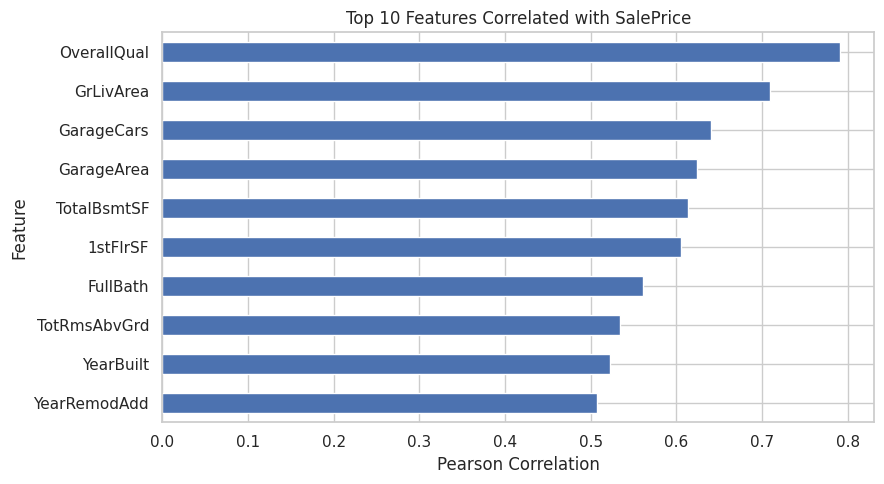

In [79]:
plt.figure(figsize=(9, 5))
top_corr.head(10).sort_values().plot(kind="barh")
plt.title("Top 10 Features Correlated with SalePrice")
plt.xlabel("Pearson Correlation")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

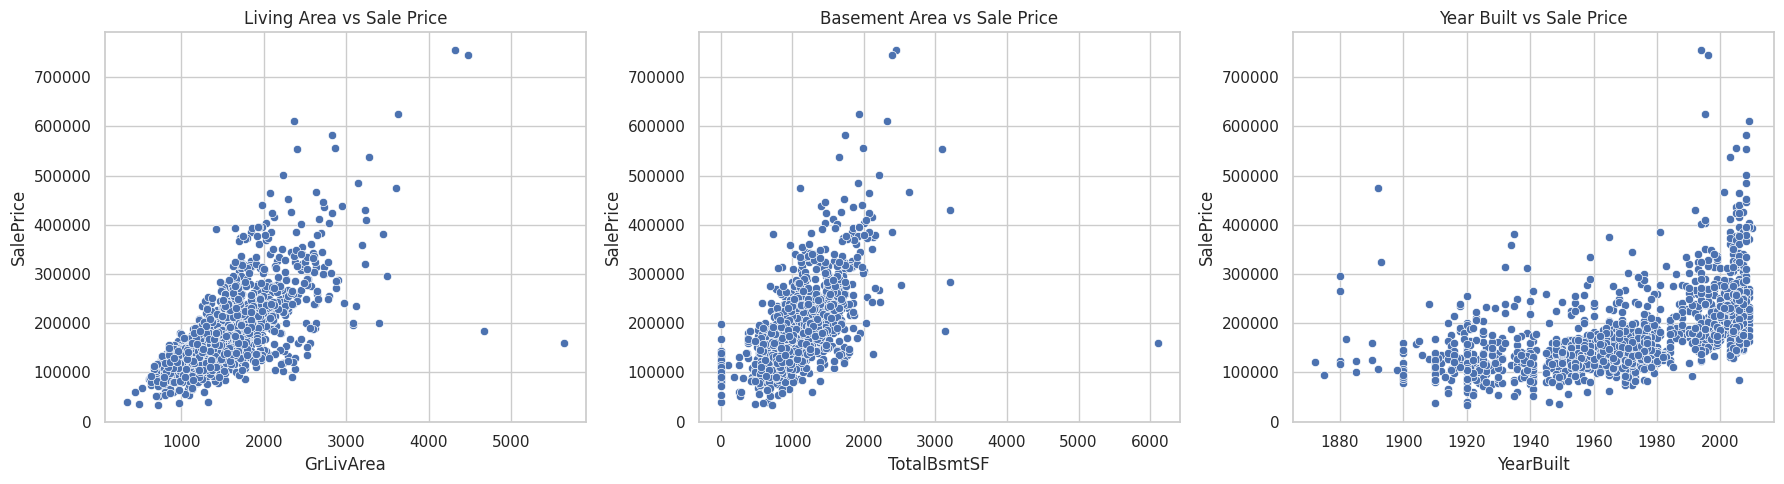

In [80]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

sns.scatterplot(data=df, x="GrLivArea", y="SalePrice", ax=axes[0])
axes[0].set_title("Living Area vs Sale Price")

sns.scatterplot(data=df, x="TotalBsmtSF", y="SalePrice", ax=axes[1])
axes[1].set_title("Basement Area vs Sale Price")

sns.scatterplot(data=df, x="YearBuilt", y="SalePrice", ax=axes[2])
axes[2].set_title("Year Built vs Sale Price")

plt.tight_layout()
plt.show()

Potential unusual large-house sales:


,Id,GrLivArea,SalePrice,OverallQual
523,524,4676,184750,10
1298,1299,5642,160000,10


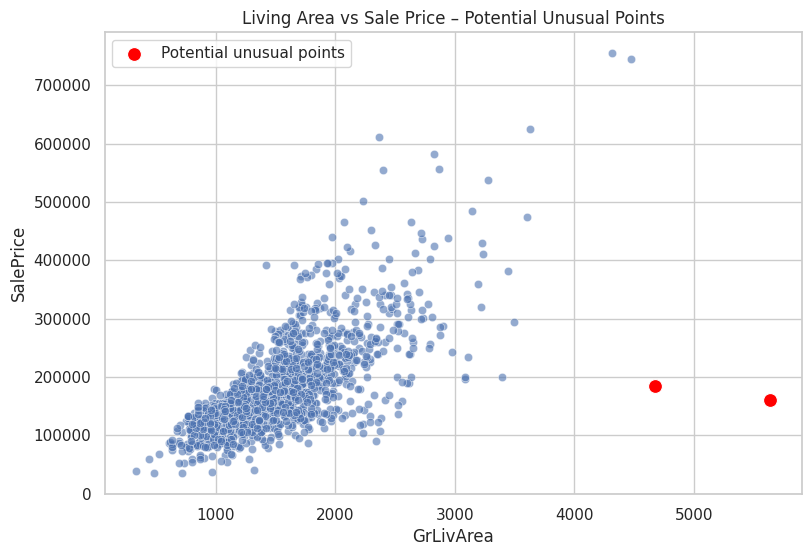

In [81]:
# Highlight unusually large houses with comparatively low sale prices
unusual_houses = df[(df["GrLivArea"] > 4000) & (df["SalePrice"] < 300000)]
print("Potential unusual large-house sales:")
display(unusual_houses[["Id", "GrLivArea", "SalePrice", "OverallQual"]])

plt.figure(figsize=(9, 6))
sns.scatterplot(data=df, x="GrLivArea", y="SalePrice", alpha=0.6)
sns.scatterplot(data=unusual_houses, x="GrLivArea", y="SalePrice",
                color="red", s=100, label="Potential unusual points")
plt.title("Living Area vs Sale Price – Potential Unusual Points")
plt.legend()
plt.show()

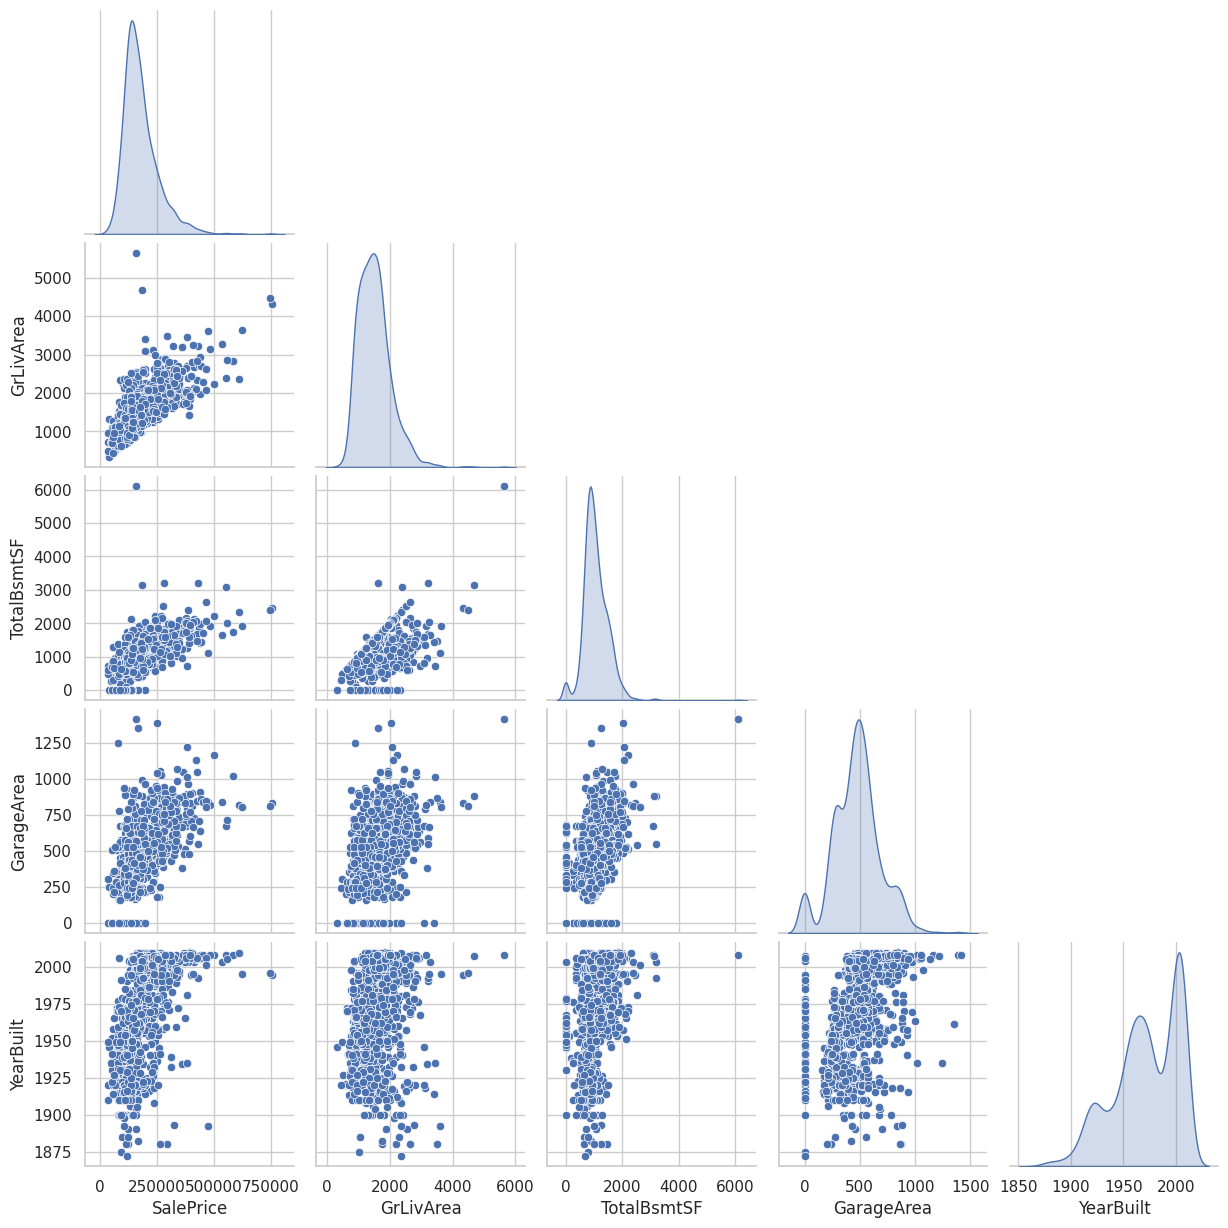

In [82]:
pair_columns = ["SalePrice", "GrLivArea", "TotalBsmtSF", "GarageArea", "YearBuilt"]
sns.pairplot(df[pair_columns].dropna(), diag_kind="kde", corner=True)
plt.show()

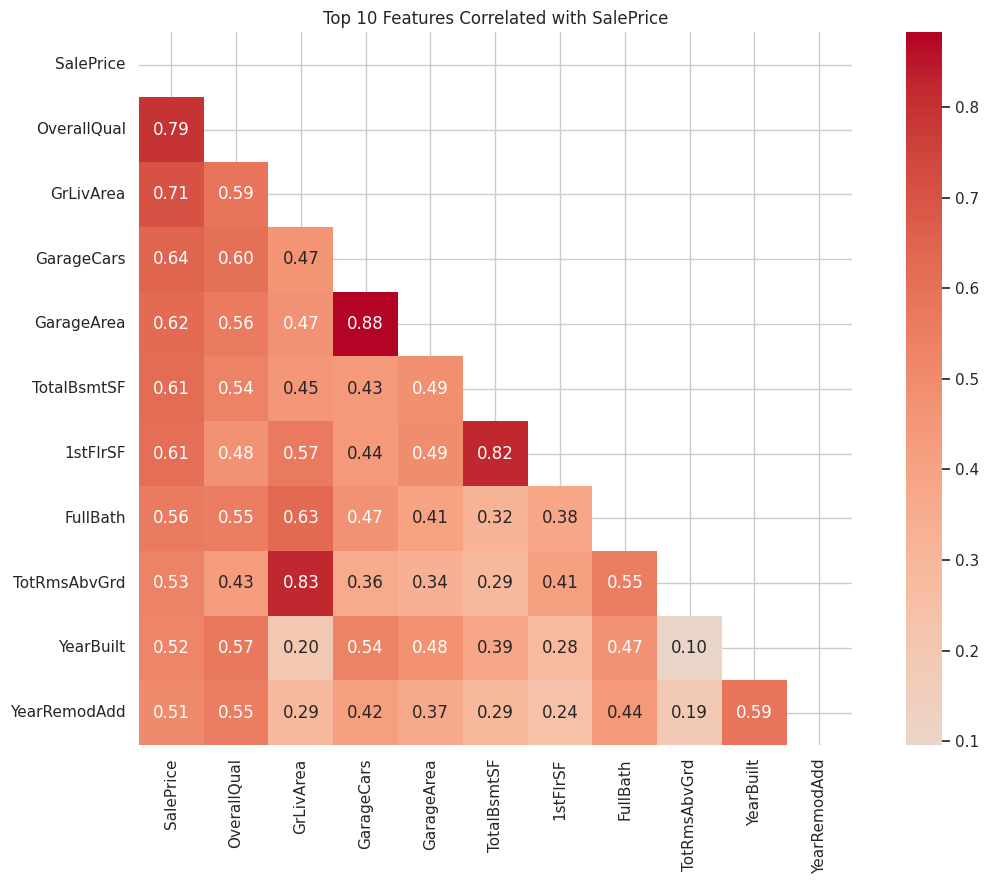

In [83]:
top10_features = ["SalePrice"] + top_corr.head(10).index.tolist()
corr_top = df[top10_features].corr()

mask = np.triu(np.ones_like(corr_top, dtype=bool))

plt.figure(figsize=(12, 9))
sns.heatmap(corr_top, mask=mask, annot=True, fmt=".2f",
            cmap="coolwarm", center=0, square=True)
plt.title("Top 10 Features Correlated with SalePrice")
plt.tight_layout()
plt.show()

In [84]:
def iqr_outliers(series):
    q1 = series.quantile(0.25)
    q3 = series.quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    return series[(series < lower) | (series > upper)].index

def zscore_outliers(series, threshold=3):
    z_scores = stats.zscore(series.dropna())
    flagged_index = series.dropna().index[np.abs(z_scores) > threshold]
    return flagged_index

for col in ["GrLivArea", "SalePrice"]:
    iqr_index = iqr_outliers(df[col].dropna())
    z_index = zscore_outliers(df[col].dropna())
    print("\\nColumn:", col)
    print("IQR outlier count:", len(iqr_index))
    print("Z-score outlier count:", len(z_index))
    print("Overlap:", len(set(iqr_index).intersection(set(z_index))))

\nColumn: GrLivArea
IQR outlier count: 31
Z-score outlier count: 16
Overlap: 16
\nColumn: SalePrice
IQR outlier count: 61
Z-score outlier count: 22
Overlap: 22


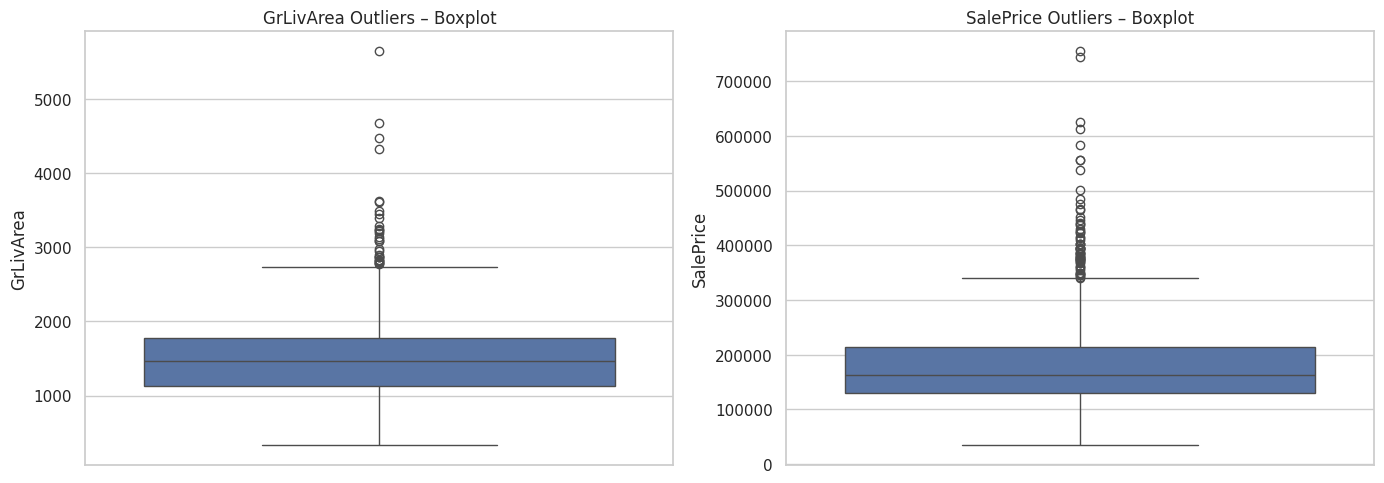

In [85]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.boxplot(y=df["GrLivArea"], ax=axes[0])
axes[0].set_title("GrLivArea Outliers – Boxplot")
sns.boxplot(y=df["SalePrice"], ax=axes[1])
axes[1].set_title("SalePrice Outliers – Boxplot")
plt.tight_layout()
plt.show()

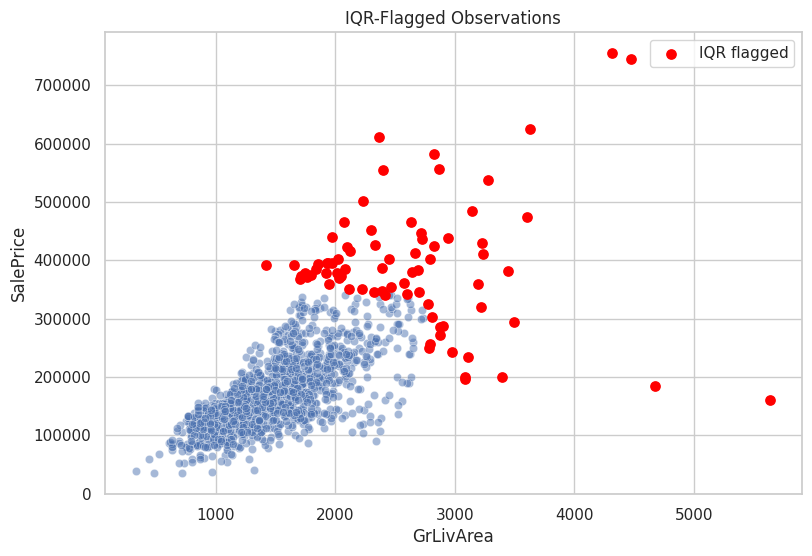

In [86]:
grliv_iqr_index = iqr_outliers(df["GrLivArea"])
price_iqr_index = iqr_outliers(df["SalePrice"])
flagged_index = sorted(set(grliv_iqr_index).union(set(price_iqr_index)))

plt.figure(figsize=(9, 6))
sns.scatterplot(data=df, x="GrLivArea", y="SalePrice", alpha=0.5)
plt.scatter(df.loc[flagged_index, "GrLivArea"],
            df.loc[flagged_index, "SalePrice"],
            color="red", label="IQR flagged", s=45)
plt.title("IQR-Flagged Observations")
plt.legend()
plt.show()

In [87]:
df_clean = df.copy()

# 1. Check and remove exact duplicate rows
duplicate_count = df_clean.duplicated().sum()
print("Duplicate rows found:", duplicate_count)
df_clean = df_clean.drop_duplicates()

# 2. Remove leading/trailing spaces from text values
text_cols = df_clean.select_dtypes(include=["object"]).columns
for col in text_cols:
    df_clean[col] = df_clean[col].apply(
        lambda value: value.strip() if isinstance(value, str) else value
    )

print("Shape after duplicate check:", df_clean.shape)

Duplicate rows found: 0
Shape after duplicate check: (1460, 81)


In [88]:
# 3. Fill missing values that mean the feature is absent
absence_columns = [
    "Alley", "MasVnrType", "BsmtQual", "BsmtCond", "BsmtExposure",
    "BsmtFinType1", "BsmtFinType2", "FireplaceQu", "GarageType",
    "GarageFinish", "GarageQual", "GarageCond", "PoolQC",
    "Fence", "MiscFeature"
]

for col in absence_columns:
    if col in df_clean.columns:
        df_clean[col] = df_clean[col].fillna("None")

print("Feature-absence columns processed.")

Feature-absence columns processed.


In [89]:
# 4. Fill LotFrontage using neighbourhood median, then overall median
if "LotFrontage" in df_clean.columns:
    df_clean["LotFrontage"] = df_clean.groupby("Neighborhood")["LotFrontage"].transform(
        lambda group: group.fillna(group.median())
    )
    df_clean["LotFrontage"] = df_clean["LotFrontage"].fillna(
        df_clean["LotFrontage"].median()
    )

# 5. Fill remaining numerical missing values with column medians
numeric_missing_cols = df_clean.select_dtypes(include=["number"]).columns[
    df_clean.select_dtypes(include=["number"]).isnull().any()
]
for col in numeric_missing_cols:
    df_clean[col] = df_clean[col].fillna(df_clean[col].median())

# 6. Fill remaining categorical missing values with mode
categorical_missing_cols = df_clean.select_dtypes(include=["object"]).columns[
    df_clean.select_dtypes(include=["object"]).isnull().any()
]
for col in categorical_missing_cols:
    mode_value = df_clean[col].mode()
    if not mode_value.empty:
        df_clean[col] = df_clean[col].fillna(mode_value[0])

print("Remaining missing values:", df_clean.isnull().sum().sum())

Remaining missing values: 0


In [90]:
# Verify data quality
print("Final shape:", df_clean.shape)
print("Duplicate rows:", df_clean.duplicated().sum())
print("Total missing values:", df_clean.isnull().sum().sum())

# Check impossible values
print("YearBuilt later than YrSold:", (df_clean["YearBuilt"] > df_clean["YrSold"]).sum())

area_columns = ["LotArea", "GrLivArea", "TotalBsmtSF", "GarageArea"]
for col in area_columns:
    print("Negative values in", col, ":", (df_clean[col] < 0).sum())

display(df_clean.isnull().sum().sort_values(ascending=False).head(10).to_frame("Missing Values"))

Final shape: (1460, 81)
Duplicate rows: 0
Total missing values: 0
YearBuilt later than YrSold: 0
Negative values in LotArea : 0
Negative values in GrLivArea : 0
Negative values in TotalBsmtSF : 0
Negative values in GarageArea : 0


,Missing Values
Id,0
MSSubClass,0
MSZoning,0
LotFrontage,0
LotArea,0
Street,0
Alley,0
LotShape,0
LandContour,0
Utilities,0


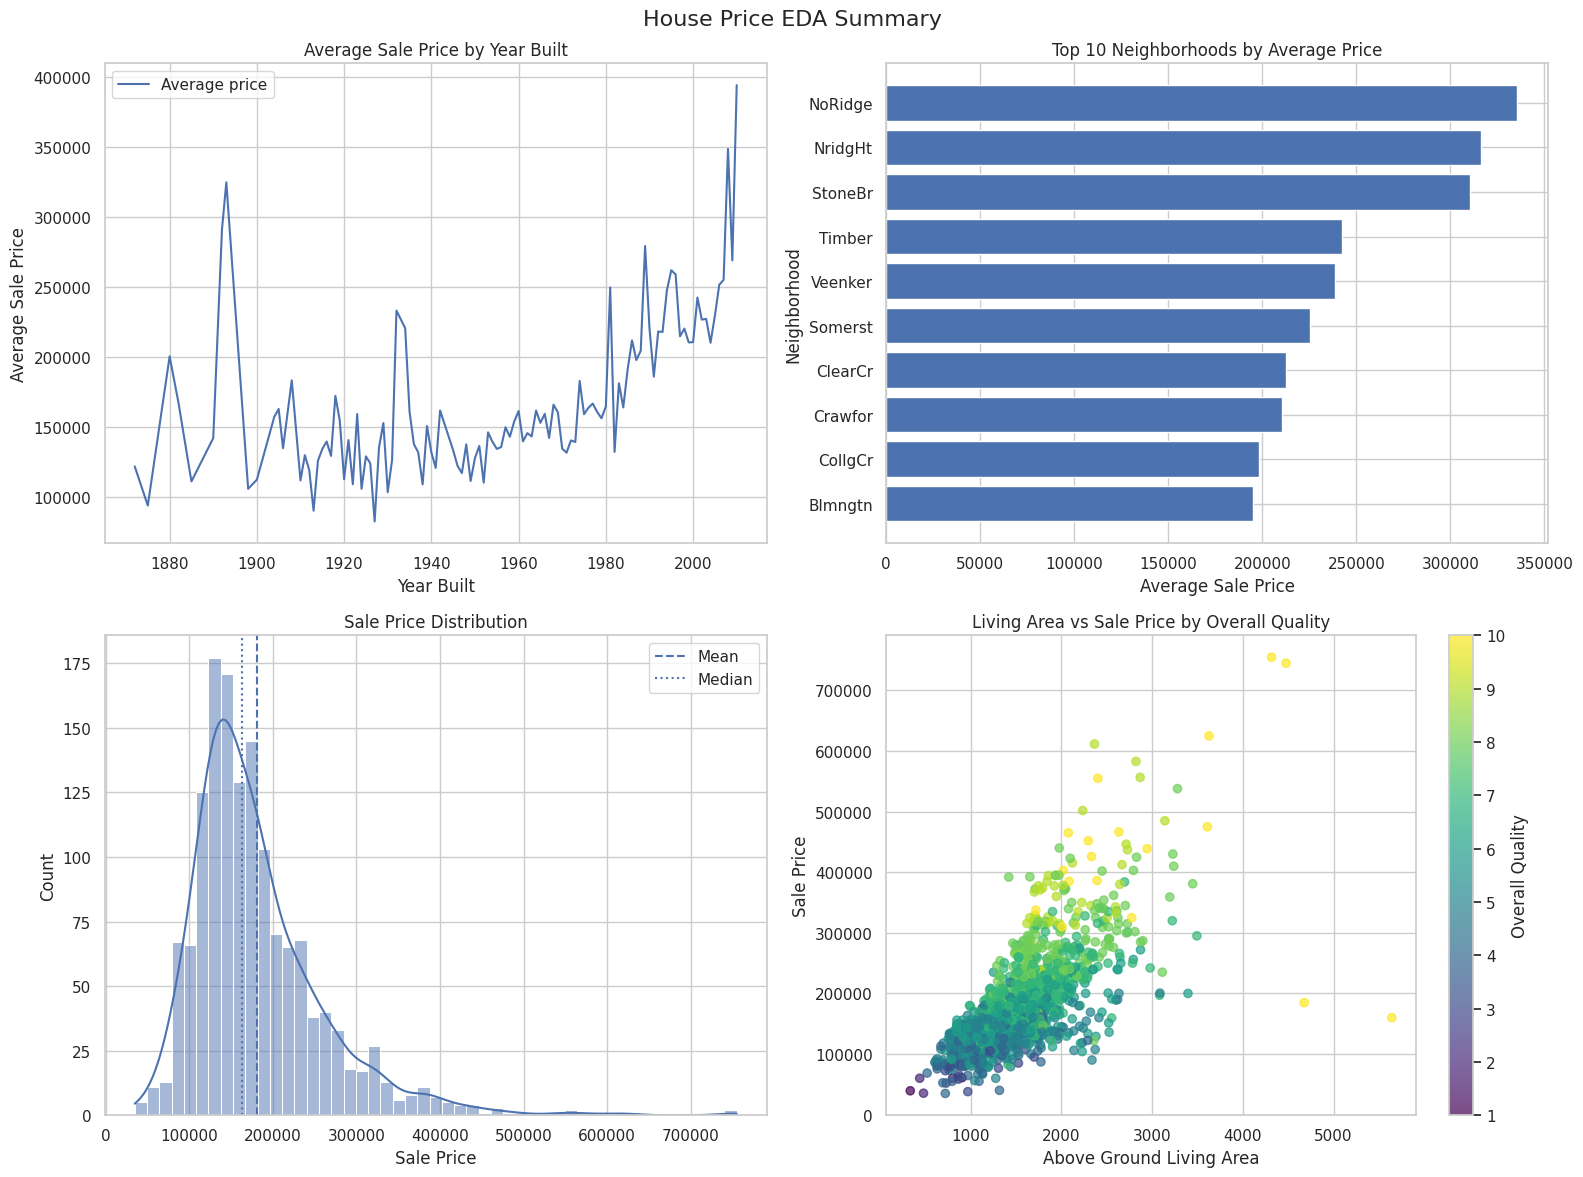

Dashboard saved as eda_dashboard.png


In [60]:
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# Panel 1: Average sale price by year built
year_price = df_clean.groupby("YearBuilt")["SalePrice"].mean()
axes[0, 0].plot(year_price.index, year_price.values, label="Average price")
axes[0, 0].set_title("Average Sale Price by Year Built")
axes[0, 0].set_xlabel("Year Built")
axes[0, 0].set_ylabel("Average Sale Price")
axes[0, 0].legend()

# Panel 2: Top 10 neighbourhoods by average sale price
neighborhood_price = df_clean.groupby("Neighborhood")["SalePrice"].mean().sort_values().tail(10)
axes[0, 1].barh(neighborhood_price.index, neighborhood_price.values)
axes[0, 1].set_title("Top 10 Neighborhoods by Average Price")
axes[0, 1].set_xlabel("Average Sale Price")
axes[0, 1].set_ylabel("Neighborhood")

# Panel 3: Sale price distribution, mean and median
sns.histplot(df_clean["SalePrice"], kde=True, ax=axes[1, 0])
axes[1, 0].axvline(df_clean["SalePrice"].mean(), linestyle="--",
                   label="Mean")
axes[1, 0].axvline(df_clean["SalePrice"].median(), linestyle=":",
                   label="Median")
axes[1, 0].set_title("Sale Price Distribution")
axes[1, 0].set_xlabel("Sale Price")
axes[1, 0].legend()

# Panel 4: Living area vs sale price coloured by quality
scatter = axes[1, 1].scatter(
    df_clean["GrLivArea"], df_clean["SalePrice"],
    c=df_clean["OverallQual"], alpha=0.7, cmap="viridis"
)
axes[1, 1].set_title("Living Area vs Sale Price by Overall Quality")
axes[1, 1].set_xlabel("Above Ground Living Area")
axes[1, 1].set_ylabel("Sale Price")
fig.colorbar(scatter, ax=axes[1, 1], label="Overall Quality")

fig.suptitle("House Price EDA Summary", fontsize=16)
plt.tight_layout()
plt.savefig("eda_dashboard.png", dpi=300, bbox_inches="tight")
plt.show()

print("Dashboard saved as eda_dashboard.png")

In [61]:
# Download the dashboard image from Google Colab
files.download("eda_dashboard.png")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [62]:
print("FINAL PROJECT SUMMARY")
print("=" * 50)
print("Number of houses:", len(df_clean))
print("Number of columns:", df_clean.shape[1])
print("Average sale price:", round(df_clean["SalePrice"].mean(), 2))
print("Median sale price:", round(df_clean["SalePrice"].median(), 2))
print("SalePrice skewness:", round(df_clean["SalePrice"].skew(), 3))
print("Most common Overall Quality:", df_clean["OverallQual"].mode()[0])

print("\\nTop 5 features correlated with SalePrice:")
display(top_corr.head(5).to_frame("Correlation"))

print("\\nTop 5 neighbourhoods by median sale price:")
display(df_clean.groupby("Neighborhood")["SalePrice"].median()
        .sort_values(ascending=False).head(5).to_frame("Median Sale Price"))

print("\\nMissing values after cleaning:", df_clean.isnull().sum().sum())
print("Duplicate rows after cleaning:", df_clean.duplicated().sum())

FINAL PROJECT SUMMARY
Number of houses: 1460
Number of columns: 81
Average sale price: 180921.2
Median sale price: 163000.0
SalePrice skewness: 1.883
Most common Overall Quality: 5
\nTop 5 features correlated with SalePrice:


,Correlation
OverallQual,0.790982
GrLivArea,0.708624
GarageCars,0.640409
GarageArea,0.623431
TotalBsmtSF,0.613581


\nTop 5 neighbourhoods by median sale price:


,Median Sale Price
Neighborhood,
NridgHt,315000.0
NoRidge,301500.0
StoneBr,278000.0
Timber,228475.0
Somerst,225500.0


\nMissing values after cleaning: 0
Duplicate rows after cleaning: 0
